# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** Grupo X · **Tema:** Atividades complementares e extensão

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [66]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/SEU_USUARIO/SEU_REPOSITORIO.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [67]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 TODO: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [68]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: Grupo X | Tema: Atividades complementares e extensão


,intenção,descrição
0,computo_horas,Contabilização de horas de extensão e de complementares
1,tipos_atividades,Tipos de atividades de extensão e de complementares
2,curricularizacao_extensao,Informações e definições sobre a curricularização de atividades de extensão ...
3,organizacao_ufms,Organização da UFMS
4,atividades_remuneradas,Atividades remuneradas


---
## 2. Dados

🔨 TODO: descreva aqui (em markdown) **como** os dados foram construídos: quem
escreveu, que fontes foram coletadas, que LLM e que *prompts* foram usados, como os
negativos difíceis foram pensados, como o teste foi obtido (ex.: formulário
respondido por N colegas).

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [69]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,humano,llm,total
intencao,,,
atividades_remuneradas,8,28,36
chitchat,39,0,39
computo_horas,47,32,79
curricularizacao_extensao,10,43,53
fora_dominio,27,1,28
organizacao_ufms,19,37,56
tipos_atividades,40,39,79
total,190,180,370


origem,coletado,humano,total
intencao,,,
atividades_remuneradas,7,11,18
chitchat,49,0,49
computo_horas,22,3,25
curricularizacao_extensao,7,7,14
fora_dominio,44,0,44
organizacao_ufms,22,0,22
tipos_atividades,25,2,27
total,176,23,199


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [ ]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

🔨 TODO: análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

In [ ]:
# 🔨 TODO

---
## 3. Representações de texto

🔨 TODO: escolha **pelo menos duas** representações para comparar. Os construtores
de `chatbot/representacoes.py` aceitam os parâmetros do `TfidfVectorizer`
(`ngram_range`, `min_df`, `stop_words`, ...). Embeddings pré-treinados
(`EmbeddingsSentenca`) são opcionais.

In [70]:
REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
    # 🔨 TODO: outras variações (ex.: com stopwords, só unigramas, embeddings...)
}

---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 TODO: compare **pelo menos três algoritmos vistos em aula**, com validação
cruzada estratificada **só no treino**. Classificadores que ainda serão
apresentados na disciplina (KNN, Naive Bayes, SVM...) podem entrar quando forem
vistos.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [71]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Naive Bayes": lambda: MultinomialNB(alpha=1.0),
    "SVM": lambda: LinearSVC(C=1.0, random_state=RANDOM_STATE ),
}

def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,SVM,0.674,0.045,0.914,1.000
1,TF-IDF palavras,Rede neural (MLP),0.672,0.042,0.914,1.000
2,TF-IDF caracteres,Árvore de decisão,0.647,0.097,0.876,1.000
3,TF-IDF caracteres,Rede neural (MLP),0.635,0.125,0.892,1.000
4,TF-IDF caracteres,Random Forest,0.631,0.014,0.922,1.000
5,TF-IDF palavras,Árvore de decisão,0.611,0.049,0.868,1.000
6,TF-IDF caracteres,Regressão logística,0.593,0.014,0.895,1.000
7,TF-IDF palavras,Random Forest,0.568,0.015,0.889,1.000
8,TF-IDF palavras,Regressão logística,0.390,0.087,0.838,1.000
9,TF-IDF palavras,SVM,0.390,0.087,0.838,1.000


Ajuste de hiperparâmetros dos melhores candidatos (`GridSearchCV`), curva
de validação e escolha justificada do modelo final de escopo.

In [72]:
busca_regressao = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={
        "classificador__C": [0.1, 1, 10, 100]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_regressao.fit(treino["texto"], treino["escopo"])
clf_regressao = busca_regressao.best_estimator_
#print(busca_regressao.best_params_, round(busca_regressao.best_score_, 3))

busca_arvore = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__max_depth": [None, 5, 10, 20, 30],
        "classificador__min_samples_split": [2, 5, 10],
        "classificador__min_samples_leaf": [1, 2, 4]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_arvore.fit(treino["texto"], treino["escopo"])
#print(busca_arvore.best_params_, round(busca_arvore.best_score_, 3))

busca_mlp = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", MLPClassifier(max_iter=500, random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__hidden_layer_sizes": [(16,), (32,)],
        "classificador__alpha": [0.0001, 0.001, 0.01]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_mlp.fit(treino["texto"], treino["escopo"])
#print(busca_mlp.best_params_, round(busca_mlp.best_score_, 3))

busca_floresta_aleatoria = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))]),
    param_grid={
        "classificador__n_estimators": [10, 20, 50],
        "classificador__max_depth": [None, 10, 20]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_floresta_aleatoria.fit(treino["texto"], treino["escopo"])
#print(busca_floresta_aleatoria.best_params_, round(busca_floresta_aleatoria.best_score_, 3))

busca_bayes = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", MultinomialNB())]),
    param_grid={
        "classificador__alpha": [0.01, 0.1, 1.0, 10.0]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_bayes.fit(treino["texto"], treino["escopo"])
#print(busca_bayes.best_params_, round(busca_bayes.best_score_, 3))

busca_svm = GridSearchCV(
    Pipeline([ ("vetorizador", tfidf_caracteres()),("classificador", LinearSVC(random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__C": [0.1, 1, 10, 100]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_svm.fit(treino["texto"], treino["escopo"])
#print(busca_svm.best_params_, round(busca_svm.best_score_, 3))

resultados = []

buscas = {
    "Regressão Logística": busca_regressao,
    "Árvore de Decisão": busca_arvore,
    "MLP": busca_mlp,
    "Random Forest": busca_floresta_aleatoria,
    "Naive Bayes": busca_bayes,
    "SVM": busca_svm
}

for nome, busca in buscas.items():
    resultados.append({
        "Algoritmo": nome,
        "Melhores parâmetros": busca.best_params_,
        "F1 macro": busca.best_score_
    })

tab_resultados = pd.DataFrame(resultados)

tab_resultados = tab_resultados.sort_values(
    "F1 macro", ascending=False
).reset_index(drop=True)

display(tab_resultados.round(3))

,Algoritmo,Melhores parâmetros,F1 macro
0,SVM,{'classificador__C': 10},0.747
1,Regressão Logística,{'classificador__C': 100},0.709
2,MLP,"{'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (16,)}",0.701
3,Random Forest,"{'classificador__max_depth': None, 'classificador__n_estimators': 10}",0.689
4,Árvore de Decisão,"{'classificador__max_depth': None, 'classificador__min_samples_leaf': 1, 'cl...",0.677
5,Naive Bayes,{'classificador__alpha': 0.01},0.570


📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros. Qual erro é mais grave **no seu domínio**?

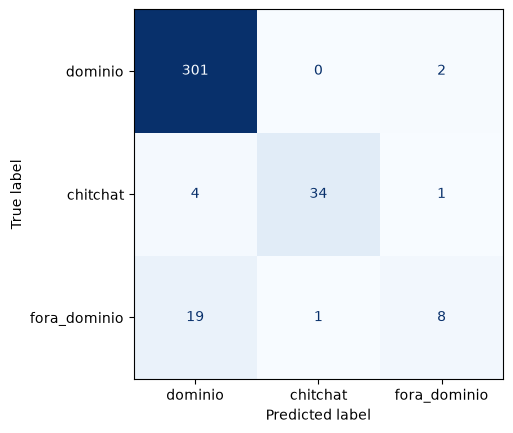

Taxa de falso positivo: 0.343
Taxa de falso negativo: 0.007


In [73]:
melhor_classificador = max(buscas, key=lambda nome: buscas[nome].best_score_)
clf_escopo = buscas[melhor_classificador].best_estimator_

prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

real = treino["escopo"].to_numpy()

falso_positivo = ((real != "dominio") & (prev_cv == "dominio")).sum()
falso_negativo = ((real == "dominio") & (prev_cv != "dominio")).sum()

total_negativas = (real != "dominio").sum()
total_dominio = (real == "dominio").sum()

print("Taxa de falso positivo:", round(falso_positivo / total_negativas, 3))
print("Taxa de falso negativo:", round(falso_negativo / total_dominio, 3))

---
## 5. Classificador de tema (intenções do domínio)


In [74]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.824,0.049,0.819,0.999
1,TF-IDF caracteres,Rede neural (MLP),0.823,0.051,0.815,1.000
2,TF-IDF caracteres,SVM,0.820,0.042,0.815,0.998
3,TF-IDF palavras,Rede neural (MLP),0.800,0.047,0.812,1.000
4,TF-IDF palavras,SVM,0.800,0.028,0.805,1.000
5,TF-IDF palavras,Regressão logística,0.786,0.034,0.799,1.000
6,TF-IDF caracteres,Random Forest,0.718,0.031,0.716,1.000
7,TF-IDF palavras,Random Forest,0.628,0.043,0.667,1.000
8,TF-IDF palavras,Naive Bayes,0.616,0.031,0.723,0.887
9,TF-IDF caracteres,Naive Bayes,0.604,0.034,0.683,0.754


In [75]:
busca_regressao_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.1, 1, 10, 100]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_regressao_tema.fit(treino_dom["texto"], treino_dom["intencao"])
clf_tema = busca_regressao_tema.best_estimator_
#print(busca_regressao_tema.best_params_, round(busca_regressao_tema.best_score_, 3))

busca_arvore_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__max_depth": [None, 5, 10, 20, 30],
        "classificador__min_samples_split": [2, 5, 10],
        "classificador__min_samples_leaf": [1, 2, 4]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_arvore_tema.fit(treino_dom["texto"], treino_dom["intencao"])
#print(busca_arvore_tema.best_params_, round(busca_arvore_tema.best_score_, 3))

busca_mlp_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", MLPClassifier(max_iter=500, random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__hidden_layer_sizes": [(16,), (32,)],
        "classificador__alpha": [0.0001, 0.001, 0.01]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_mlp_tema.fit(treino_dom["texto"], treino_dom["intencao"])
#print(busca_mlp_tema.best_params_, round(busca_mlp_tema.best_score_, 3))

busca_floresta_aleatoria_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))]),
    param_grid={
        "classificador__n_estimators": [10, 20, 50],
        "classificador__max_depth": [None, 10, 20]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_floresta_aleatoria_tema.fit(treino_dom["texto"], treino_dom["intencao"])
#print(busca_floresta_aleatoria_tema.best_params_, round(busca_floresta_aleatoria_tema.best_score_, 3))

busca_bayes_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),("classificador", MultinomialNB())]),
    param_grid={
        "classificador__alpha": [0.01, 0.1, 1.0, 10.0]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_bayes_tema.fit(treino_dom["texto"], treino_dom["intencao"])
#print(busca_bayes_tema.best_params_, round(busca_bayes_tema.best_score_, 3))

busca_svm_tema = GridSearchCV(
    Pipeline([ ("vetorizador", tfidf_caracteres()),("classificador", LinearSVC(random_state=RANDOM_STATE))]),
    param_grid={
        "classificador__C": [0.1, 1, 10, 100]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1,
)

busca_svm_tema.fit(treino_dom["texto"], treino_dom["intencao"])
#print(busca_svm_tema.best_params_, round(busca_svm_tema.best_score_, 3))

resultados = []

buscas = {
    "Regressão Logística": busca_regressao_tema,
    "Árvore de Decisão": busca_arvore_tema,
    "MLP": busca_mlp_tema,
    "Random Forest": busca_floresta_aleatoria_tema,
    "Naive Bayes": busca_bayes_tema,
    "SVM": busca_svm_tema
}

for nome, busca in buscas.items():
    resultados.append({
        "Algoritmo": nome,
        "Melhores parâmetros": busca.best_params_,
        "F1 macro": busca.best_score_
    })

tab_resultados = pd.DataFrame(resultados)

tab_resultados = tab_resultados.sort_values(
    "F1 macro", ascending=False
).reset_index(drop=True)

display(tab_resultados.round(3))

,Algoritmo,Melhores parâmetros,F1 macro
0,Regressão Logística,{'classificador__C': 10},0.824
1,SVM,{'classificador__C': 100},0.821
2,MLP,"{'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (16,)}",0.821
3,Naive Bayes,{'classificador__alpha': 0.1},0.804
4,Random Forest,"{'classificador__max_depth': 20, 'classificador__n_estimators': 50}",0.701
5,Árvore de Decisão,"{'classificador__max_depth': 5, 'classificador__min_samples_leaf': 4, 'class...",0.594


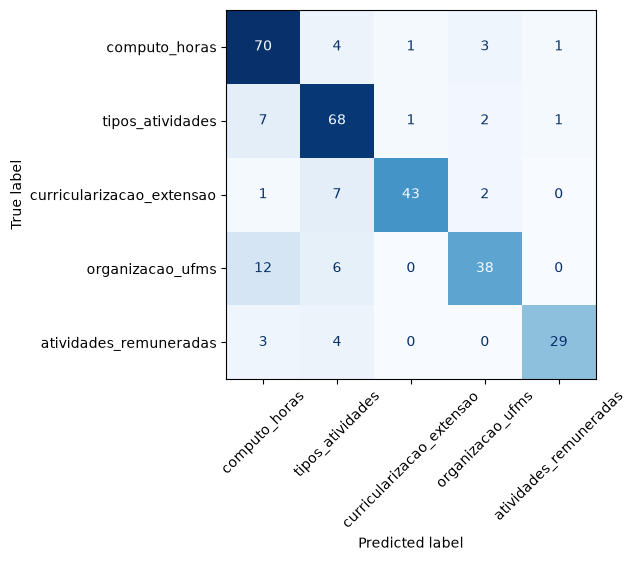

                           precision    recall  f1-score   support

   atividades_remuneradas       0.94      0.81      0.87        36
            computo_horas       0.75      0.89      0.81        79
curricularizacao_extensao       0.96      0.81      0.88        53
         organizacao_ufms       0.84      0.68      0.75        56
         tipos_atividades       0.76      0.86      0.81        79

                 accuracy                           0.82       303
                macro avg       0.85      0.81      0.82       303
             weighted avg       0.83      0.82      0.82       303

Taxa de falso positivo: 0.343
Taxa de falso negativo: 0.007


In [76]:
melhor_classificador = max(buscas, key=lambda nome: buscas[nome].best_score_)
clf_tema = buscas[melhor_classificador].best_estimator_

prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

real = treino["escopo"].to_numpy()

falso_positivo = ((real != "dominio") & (prev_cv == "dominio")).sum()
falso_negativo = ((real == "dominio") & (prev_cv != "dominio")).sum()

total_negativas = (real != "dominio").sum()
total_dominio = (real == "dominio").sum()

print("Taxa de falso positivo:", round(falso_positivo / total_negativas, 3))
print("Taxa de falso negativo:", round(falso_negativo / total_dominio, 3))

---
## 6. Limiar de confiança

## Escolhemos o limiar 0.5, pois apresenta um crescimento porcentual mais significativo em relação ao número de perguntas respondidas

In [78]:
proba = cross_val_predict(
    clf_tema,
    treino_dom["texto"],
    treino_dom["intencao"],
    cv=cv,
    method="predict_proba"
)

confianca = proba.max(axis=1)

classes = clf_tema.classes_

acertou = (
    classes[proba.argmax(axis=1)]
    == treino_dom["intencao"].to_numpy()
)

resultados_limiar = []

for limiar in [0.3, 0.4, 0.5, 0.6]:
    resp = confianca >= limiar
    esclarecer = ~resp

    resultados_limiar.append({
        "Limiar": limiar,
        "Mensagens respondidas": resp.sum(),
        "Percentual respondido": resp.mean(),
        "Acurácia das respostas": acertou[resp].mean(),
        "Erros evitados": (esclarecer & ~acertou).sum(),
        "Acertos encaminhados": (esclarecer & acertou).sum()
    })

tab_limiar = pd.DataFrame(resultados_limiar)

display(tab_limiar.round(3))

,Limiar,Mensagens respondidas,Percentual respondido,Acurácia das respostas,Erros evitados,Acertos encaminhados
0,0.3,300,0.990,0.827,3,0
1,0.4,279,0.921,0.832,8,16
2,0.5,250,0.825,0.872,23,30
3,0.6,207,0.683,0.908,36,60


---
## 7. Salvar os modelos finais

In [77]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [ ]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

# 🔨 TODO: teste a busca com perguntas do seu domínio (não gasta créditos)
pergunta, intencao = "TODO: uma pergunta do seu domínio", config.nomes_intencoes[0]
for tr, sim in base.buscar(pergunta, intencao=intencao):
    print(f"{sim:.2f}  {tr.fonte} | {tr.texto[:80]!r}")

In [ ]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

In [ ]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in ["oi!", "TODO: escreva mensagens do seu domínio", "obrigado"]:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [ ]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [36]:
!{sys.executable} scripts/verificar_entrega.py

[ OK  ] grupo.yaml lido: grupo 'Grupo X', tema 'Atividades complementares e extensão'
[ OK  ] 5 intenções definidas (exigido: 5 a 10)
[ OK  ] 4 integrante(s) com nome (exigido: 3 a 4)
[ERRO ] o grupo.yaml ainda contém marcações TODO
[ OK  ] treino.csv: 370 mensagens, formato válido
[ OK  ] teste.csv: 199 mensagens, formato válido
[ERRO ] treino: mínimo de 50 exemplos por intenção - abaixo: {'atividades_remuneradas': 36}
[ERRO ] treino: 39 exemplos de chitchat (mínimo 100)
[ERRO ] treino: 28 exemplos de fora_dominio (mínimo 150)
[ OK  ] treino: 51% das frases escritas por pessoas ou coletadas (mínimo 20%)
[ERRO ] teste: mínimo de 15 exemplos por intenção - abaixo: {'curricularizacao_extensao': 14}
[ OK  ] teste: 49 exemplos de chitchat (mínimo 30)
[ OK  ] teste: 44 exemplos de fora_dominio (mínimo 40)
[ OK  ] teste: todas as frases escritas por pessoas ou coletadas
[ OK  ] nenhuma frase do teste repetida no treino
[ERRO ] modelos/grafo: FileNotFoundError: Modelo não encontrado: D:\Coisa

Traceback (most recent call last):
  File "d:\Coisas de Universidade\IA-2026-02-TP-Chatbot\scripts\verificar_entrega.py", line 155, in main
    clf_escopo, clf_tema = carregar_classificadores(config)
                           ~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^
  File "D:\Coisas de Universidade\IA-2026-02-TP-Chatbot\chatbot\modelos.py", line 65, in carregar_classificadores
    raise FileNotFoundError(
    ...<2 lines>...
    )
FileNotFoundError: Modelo não encontrado: D:\Coisas de Universidade\IA-2026-02-TP-Chatbot\modelos\escopo.joblib. Treine e salve os classificadores antes (veja a seção 'Salvar os modelos' do notebook).
incorrect startxref pointer(1)
parsing for Object Streams
Error -3 while decompressing data: incorrect header check
Error -3 while decompressing data: incorrect header check
Error -3 while decompressing data: incorrect header check
Error -3 while decompressing data: incorrect header check
Error -3 while decompressing data: incorrect header check
Error -3 while decompr